# Alberta international students, PALs and study permits
Preliminary analysis • sources downloaded 12 October 2026 UTC

**Research question:** What can public data tell us about who received PAL letters or study permits, especially master's and doctoral students and Alberta institutions?

**Finding:** Public sources support institution-level permit-holder counts, graduate versus other PAL allocations, a small number of actual PAL issuance disclosures, and detailed student enrolment profiles. They do **not** establish a complete Alberta institution × master's/doctoral × PAL-issued/submitted/permit-approved dataset. No individual recipient identities are available in these aggregate sources.

This notebook keeps each measure separate. Enrolment describes student populations; it is not evidence that those students received a PAL or a new permit. A master's category includes more than MA degrees; doctoral categories should not be relabelled PhD-only.

## Definitions and coverage
| Measure | Meaning | Main limitation |
|---|---|---|
| PAL allocation | Planned maximum application spaces | Not letters issued or permits granted |
| PAL issuance | Letters produced/reported by province or institution | Not proof of an IRCC submission |
| Permit-effective holders | Holders whose study permits became effective during the period | Not restricted to new approvals/arrivals; not enrolment |
| Year-end holders | Administrative stock at December 31 | Destination and validity do not establish current attendance |
| Alberta LERS headcount | Annual international enrolment in reporting institutions' approved programs | Overlapping program/institution memberships; reporting changes |
| Statistics Canada PSIS | Fall-snapshot program enrolments | Not unique people or full-year headcount; rounded to 3 |

Calendar series cover 2020–2025 and separately labelled January–July 2026. Alberta annual enrolment covers 2019–20 through 2024–25. PALs began in 2024: earlier years are not applicable, not zero.


In [1]:
from pathlib import Path
import json, runpy, pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().parent
assert (ROOT/'focus_2020_latest').exists(), 'Execute from the analysis folder'
runpy.run_path(str(ROOT/'scripts/preliminary_analysis.py'))
T = ROOT/'analysis/tables'
C = ROOT/'analysis/cleaned'
pd.options.display.max_columns = 12
pd.options.display.max_rows = 30
pd.options.display.float_format = '{:,.2f}'.format
def table(name): return pd.read_csv(T/(name+'.csv'))


{
  "cleaned_files": 15,
  "cleaned_rows": 4302,
  "checks": 44,
  "source_discrepancies": [
    {
      "check": "2024 provincial allocation sum minus published total",
      "passed": false,
      "detail": -1,
      "severity": "source_discrepancy"
    }
  ],
  "alberta_system_trend": [
    {
      "academic_year": "2019-2020",
      "system_headcount": 28246,
      "year_over_year_pct": null
    },
    {
      "academic_year": "2020-2021",
      "system_headcount": 27028,
      "year_over_year_pct": -4.312114989733063
    },
    {
      "academic_year": "2021-2022",
      "system_headcount": 29991,
      "year_over_year_pct": 10.96270534260766
    },
    {
      "academic_year": "2022-2023",
      "system_headcount": 37076,
      "year_over_year_pct": 23.623753792804504
    },
    {
      "academic_year": "2023-2024",
      "system_headcount": 48311,
      "year_over_year_pct": 30.30262164203259
    },
    {
      "academic_year": "2024-2025",
      "system_headcount": 50164,
     

## PALs: graduate allocation and actual issuance
In 2025 Alberta had **5,256 graduate application spaces**, master's and doctoral combined, and **42,082 other spaces**. The graduate share was **11.1%**, versus **21.8% nationally**. This is the allocation mix, not the observed recipient mix. The 2025 planning figures for expected permits were 3,887 graduate and 28,773 other, not actual approvals.

Graduate applicability changed: master's/doctoral applicants were exempt in 2024, generally included from January 22, 2025, and degree-granting master's/doctoral programs at public DLIs became exempt from January 1, 2026. Other exemptions also apply. The allocation totals across these years therefore cover different groups.

Sources: [2024 IRCC briefing](https://www.canada.ca/en/immigration-refugees-citizenship/corporate/transparency/committees/cimm-feb-28-2024/study-permit-application-caps.html), [2025 allocation announcement](https://www.canada.ca/en/immigration-refugees-citizenship/news/notices/2025-provincial-territorial-allocations-under-international-student-cap.html), [2025 Gazette](https://gazette.gc.ca/rp-pr/p1/2025/2025-01-18/html/notice-avis-eng.html), [2026 announcement](https://www.canada.ca/en/immigration-refugees-citizenship/news/notices/2026-provincial-territorial-allocations-under-international-student-cap.html).


In [2]:
display(table('alberta_pal_allocations_2024_2026')[['year','application_spaces','expected_permits_pal_required','graduate_application_spaces']])
g=table('pal_2025_graduate_allocation_by_province')
display(g[['province','graduate_application_spaces','other_application_spaces','graduate_share_of_allocation_pct']])
display(table('alberta_pal_actuals_and_evidence')[['entity','period','metric','value']])


,year,application_spaces,expected_permits_pal_required,graduate_application_spaces
0,2024,40894,24537,NaN
1,2025,47338,32660,"5,256.00"
2,2026,32271,21582,NaN


,province,graduate_application_spaces,other_application_spaces,graduate_share_of_allocation_pct
0,Alberta,5256,42082,11.10
1,British Columbia,28333,47754,37.24
2,Manitoba,1980,16611,10.65
3,New Brunswick,3112,11673,21.05
4,Newfoundland and Labrador,2648,6534,28.84
5,Northwest Territories,0,705,0.00
6,Nova Scotia,4191,14411,22.53
7,Nunavut,0,0,NaN
8,Ontario,32579,149011,17.94
9,Prince Edward Island,391,2044,16.06


,entity,period,metric,value
0,Alberta,Fiscal 2024-25,PALs issued by provincial portal,"26,089.00"
1,University of Lethbridge,2024-01-22 to 2025-01-21,Allocated study permit applications,"2,687.00"
2,University of Calgary,2024 allocation cycle,Qualitative PAL underuse,NaN
3,University of Lethbridge,2024 (last year in February2025 minutes),PALs issued,"1,784.00"
4,MacEwan University,2025 expected,Expected PAL allocation,"1,500.00"
5,University of Lethbridge,2024 admissions context,PAL submission count unknown,NaN


The Alberta annual report states: **“the portal issued 26,089 provincial attestation letters”** in fiscal 2024–25 ([PDF, page 58](https://open.alberta.ca/dataset/9c785a4b-e79a-465b-8fa9-322a322f1f15/resource/f0581939-0ba9-4bd8-8290-3148f224ec76/download/ae-annual-report-2024-2025.pdf)). This cannot be divided by a calendar-year allocation to estimate utilization.

Lethbridge reported **“We issued 1,784 PALS last year”** in February 2025 ([minutes, page 2](https://www.ulethbridge.ca/sites/default/files/2025-03/gfc-approved_minutes_feb_3_2025_2.pdf)). Its separate fee report says **“we don’t know how many used them to apply for a study permit”** ([page 54](https://www.ulethbridge.ca/sites/default/files/2024-12/2025-2026-proposed-fees-and-rates-report-full-final.pdf)). No master's/doctoral breakdown accompanies these counts.

Calgary disclosed underuse without publishing an exact numerator/denominator. MacEwan's 1,500 letters are an expectation for 2025, not confirmed issuance. These sparse institutional observations must not be treated as a complete university ranking.


## Actual permit-holder counts by Alberta institution
These counts are from IRCC's post-secondary DLI workbook, copied from published annual total columns rather than summed from months. Values are rounded to five, and suppressed cells remain missing. Institutional categories can overlap in aggregate counts; retain the published provincial totals.

Alberta's published post-secondary DLI total fell from **25,570 in 2024 to 17,250 in 2025**, a **32.5% decrease**. That change describes this administrative series. It does not establish why the decline happened or a PAL-to-permit conversion rate.

Source: [IRCC DLI administrative-type workbook](https://www.ircc.canada.ca/opendata-donneesouvertes/data/EN_ODP-TR-Study-DLI_name_PT_Admin_type.xlsx).


In [3]:
p=table('alberta_institution_permit_effective_2020_2025')
display(p[['institution','2020','2021','2022','2023','2024','2025','change_2024_to_2025_pct']].head(15))
display(table('alberta_postsecondary_permit_effective_totals')[['year','period','administrative_type','row_type','value']])


,institution,2020,2021,2022,2023,2024,2025,change_2024_to_2025_pct
0,University of Alberta,"2,250.00","4,380.00","4,025.00","3,875.00","3,200.00","3,615.00",12.97
1,University of Calgary,"1,275.00","3,470.00","3,495.00","3,475.00","2,710.00","2,580.00",-4.80
2,Southern Alberta Institute of Technology,920.00,"2,090.00","3,120.00","5,205.00","3,670.00","2,185.00",-40.46
3,NorQuest College,580.00,"1,580.00","1,795.00","2,955.00","1,565.00","1,540.00",-1.60
4,Bow Valley College,990.00,"1,595.00","1,610.00","1,940.00","1,620.00","1,400.00",-13.58
5,Northern Alberta Institute of Technology,760.00,"1,230.00","1,485.00","2,225.00","2,540.00","1,350.00",-46.85
6,Portage College,5.00,40.00,255.00,"2,210.00","4,170.00",745.00,-82.13
7,MacEwan University,360.00,515.00,870.00,"1,150.00","1,010.00",730.00,-27.72
8,University of Lethbridge,185.00,450.00,595.00,"1,095.00",675.00,500.00,-25.93
9,Red Deer Polytechnic,135.00,335.00,550.00,835.00,855.00,440.00,-48.54


,year,period,administrative_type,row_type,value
0,2020,Calendar year,All types,province_total,8770
1,2020,Calendar year,Private Institution,administrative_type_total,335
2,2020,Calendar year,Public Institution,administrative_type_total,8445
3,2021,Calendar year,All types,province_total,17640
4,2021,Calendar year,Private Institution,administrative_type_total,300
5,2021,Calendar year,Public Institution,administrative_type_total,17340
6,2022,Calendar year,All types,province_total,20305
7,2022,Calendar year,Private Institution,administrative_type_total,390
8,2022,Calendar year,Public Institution,administrative_type_total,19915
9,2023,Calendar year,All types,province_total,29630


## How many international students, and at what level?
The Alberta annual system headcount was **50,164 in 2024–25**, up **3.8%** from 48,311 in 2023–24. It was 28,246 in 2019–20. Growth over this window is descriptive and affected by reporting changes; it is not a constant-coverage estimate of students physically living in Alberta.

In 2024–25 the program-level headcounts were **10,794 bachelor's**, **4,747 master's**, and **2,875 doctoral**. The standard-diploma count was **22,695**, illustrating why a university-only analysis misses much of this population. A graduate certificate or diploma must not be reclassified as a master's degree. No table here identifies MA separately from MSc, MBA or other master's degrees.

Source: [Alberta LERS international headcount workbook](https://open.alberta.ca/dataset/9d5b3f25-3fa5-4600-a48c-ba200ca6c4a8/resource/5776c043-d497-45bb-acb4-f63293443043/download/international-headcount-enrolment-within-the-alberta-post-secondary-education-system.xlsx), including its dictionary and reporting-change sheets.


In [4]:
display(table('alberta_system_enrolment_trend'))
d=table('alberta_degree_enrolment_trend')
display(d.pivot(index='academic_year',columns='program_type',values='headcount'))
display(table('alberta_institution_enrolment_2024_25')[['post_secondary_institution','headcount']].head(15))
display(table('alberta_2024_25_age_group')[['age_group','headcount']])
display(table('alberta_2024_25_gender')[['gender','headcount']])
display(table('alberta_2024_25_field_of_study')[['stem_and_bhase_subgroups','headcount']])


,academic_year,system_headcount,year_over_year_pct
0,2019-2020,28246,NaN
1,2020-2021,27028,-4.31
2,2021-2022,29991,10.96
3,2022-2023,37076,23.62
4,2023-2024,48311,30.30
5,2024-2025,50164,3.84


program_type,Bachelor's,Doctoral,Master's
academic_year,,,
2019-2020,9214,2737,3771
2020-2021,9622,2729,3398
2021-2022,10561,2869,3784
2022-2023,11084,3017,4417
2023-2024,11420,2984,5076
2024-2025,10794,2875,4747


,post_secondary_institution,headcount
0,University of Alberta,8664
1,Southern Alberta Institute of Technology,8061
2,University of Calgary,7223
3,NorQuest College,4970
4,Northern Alberta Institute of Technology,4916
5,Bow Valley College,3347
6,Athabasca University,2664
7,University of Lethbridge,1844
8,Keyano College,1640
9,Lethbridge Polytechnic,1365


,age_group,headcount
0,0-17,573
1,18-24,30301
2,25-34,12843
3,35-44,5245
4,45-54,1096
5,55+,106
6,All Age Groups,50164


,gender,headcount
0,Female,24204
1,Male,25867
2,Other Gender,66
3,Unspecified,27
4,All Genders,50164


,stem_and_bhase_subgroups,headcount
0,a.1 - Science and science technology,2885
1,a.2 - Engineering and engineering technology,6863
2,a.3 - Mathematics and computer and information...,6161
3,All STEM Subgroups,15846
4,b.1 - Business and administration,16598
5,b.2 - Arts and humanities,5844
6,b.3 - Social and behavioural sciences,4083
7,b.4 - Legal professions and studies,407
8,b.5 - Health care,3107
9,b.6 - Education and teaching,275


**Interpretation:** 18–24-year-olds account for 60.4% of the annual system headcount; 25–34-year-olds account for 25.6%. The recorded female/male counts are 24,204 and 25,867, with 66 other-gender and 27 unspecified records. These are the source's gender categories, not inferred identities. Business and administration has 16,598 enrolments/headcounts in the LERS field grouping, engineering/technology 6,863, and mathematics/computer/information science 6,161. Field memberships overlap; do not sum them as unique people.

**Comparability warnings:** Athabasca's 2024–25 reporting window spans January 2024–April 2025; NorQuest's spring 2024 is included in two reporting years; MaKami first appears in 2024–25. The institution sum is 50,606, exceeding the deduplicated system total by 442 memberships. That excess is not 442 identifiable duplicate students. The raw workbook's reporting-change sheet contains additional earlier changes.


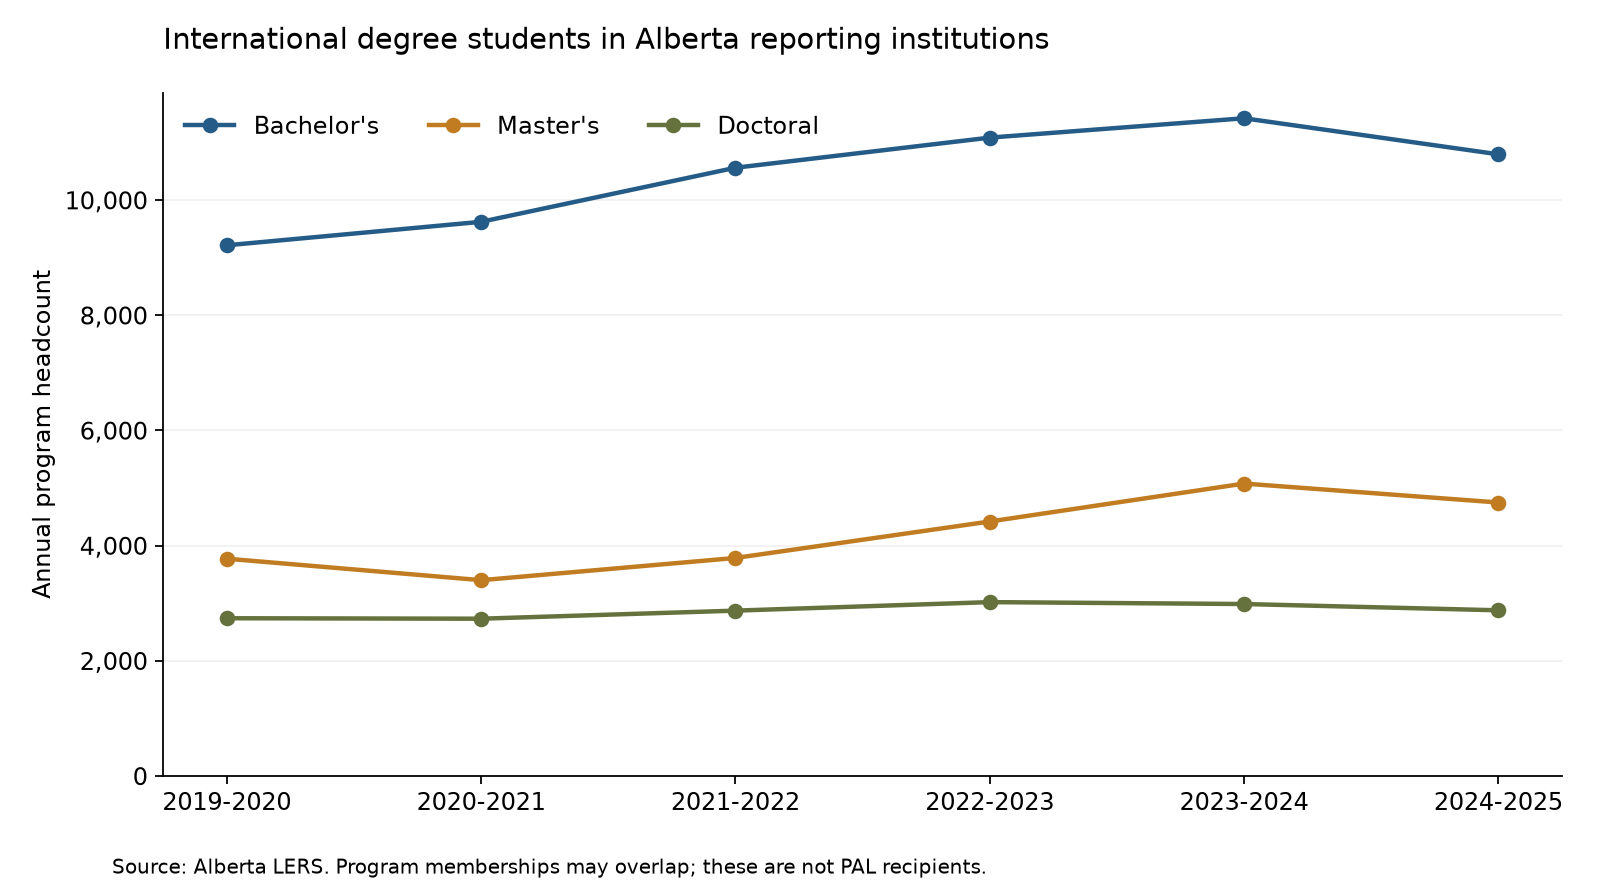

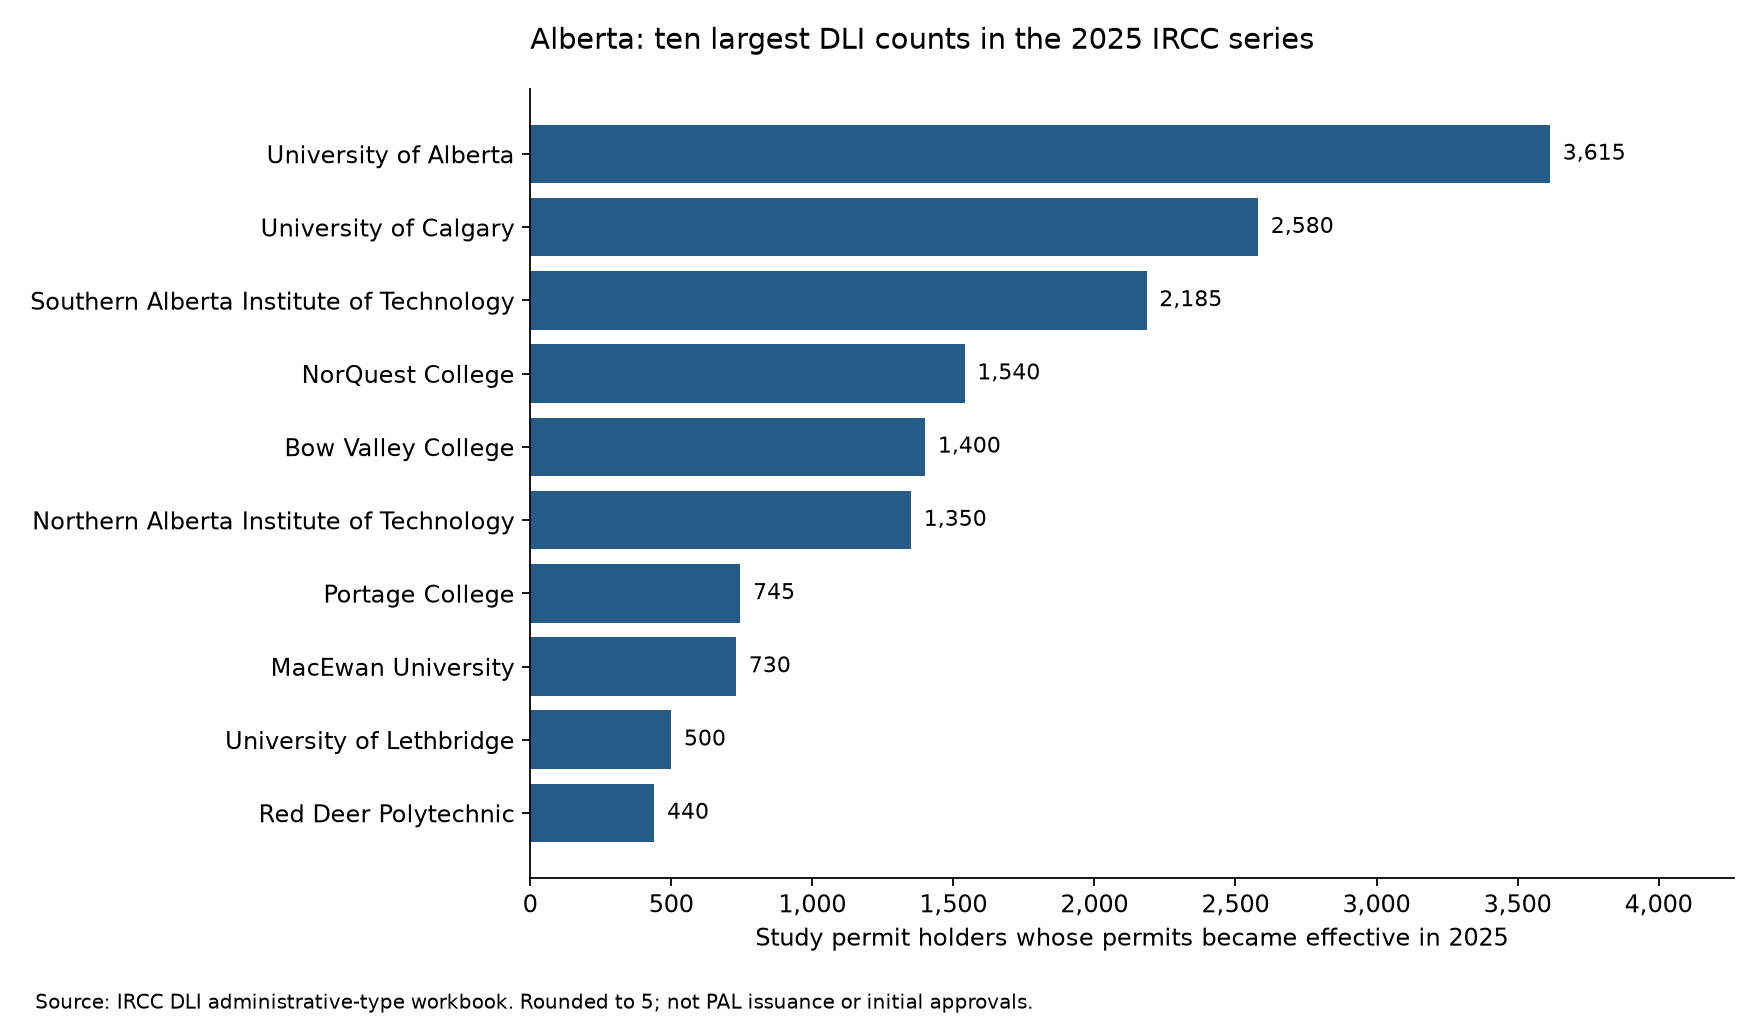

In [5]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
FIG=ROOT/'analysis/figures'; FIG.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(figsize=(10,5.6))
colors={"Bachelor's":'#245b87',"Master's":'#c17c22','Doctoral':'#65723d'}
for group in ["Bachelor's","Master's",'Doctoral']:
    z=d[d.program_type.eq(group)].sort_values('academic_year')
    ax.plot(z.academic_year,z.headcount,marker='o',label=group,color=colors[group],linewidth=2)
ax.set_ylim(bottom=0); ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.set_title('International degree students in Alberta reporting institutions',loc='left',pad=20)
ax.set_ylabel('Annual program headcount'); ax.legend(frameon=False,ncol=3,loc='upper left')
ax.grid(axis='y',alpha=.18)
fig.text(.07,.025,'Source: Alberta LERS. Program memberships may overlap; these are not PAL recipients.',fontsize=9)
fig.tight_layout(rect=(0,.06,1,1));fig.savefig(FIG/'alberta_degree_trends.png',dpi=160);plt.close(fig)
display(Image(filename=str(FIG/'alberta_degree_trends.png')))

z=p.head(10).sort_values('2025')
fig,ax=plt.subplots(figsize=(11,6.4))
ax.barh(z.institution,z['2025'],color='#245b87')
for i,v in enumerate(z['2025']):ax.text(v+45,i,f'{v:,.0f}',va='center',fontsize=10)
ax.set_xlim(0,z['2025'].max()*1.18);ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.set_title('Alberta: ten largest DLI counts in the 2025 IRCC series',loc='left',pad=18)
ax.set_xlabel('Study permit holders whose permits became effective in 2025')
fig.text(.02,.015,'Source: IRCC DLI administrative-type workbook. Rounded to 5; not PAL issuance or initial approvals.',fontsize=9)
fig.tight_layout(rect=(0,.045,1,1));fig.savefig(FIG/'alberta_dli_permits_2025.png',dpi=160);plt.close(fig)
display(Image(filename=str(FIG/'alberta_dli_permits_2025.png')))


## Source agreement and limits
The older IRCC year-end workbook reports **71,545 Alberta holders on December 31, 2024**, while Alberta LERS reports **50,164 annual international students in 2024–25**, and PSIS reports **41,007 fall-snapshot enrolments** in Alberta in 2024–25. These are different measures, scopes and periods; their difference must not be called missing students or unused PALs.

The latest national IRCC monthly series reports **590,205 study permit holders at July 31, 2026**. Its scope and vintage differ from the older year-end workbook, including treatment of asylum-related groups; do not splice them into one stock trend. Likewise, all-study-level provincial permit counts include students outside the post-secondary DLI series.

Sources: [IRCC year-end study-level workbook](https://www.ircc.canada.ca/opendata-donneesouvertes/data/EN_ODP_annual-TR-Study-IS_PT_study_level_year_end.xlsx), [IRCC monthly stock](https://www.canada.ca/en/immigration-refugees-citizenship/corporate/reports-statistics/statistics-open-data/immigration-stats/students-workers.html), PSIS table 37-10-0086 in the source manifest.


In [6]:
display(table('canada_province_year_end_stock_2020_2024').query("province in ['Alberta','Canada']")[['province','year','value']])
checks=json.loads((ROOT/'analysis/validation_checks.json').read_text())
display(pd.DataFrame([{'check':x['check'],'passed':x['passed'],'detail':str(x['detail'])} for x in checks if not x['passed']]))
print(f'{len(checks)} checks; {sum(x["passed"] for x in checks)} passed; known source discrepancies retained.')


,province,year,value
0,Alberta,2020,27680
1,Alberta,2021,32440
2,Alberta,2022,43595
3,Alberta,2023,62890
4,Alberta,2024,71545
10,Canada,2020,527145
11,Canada,2021,616365
12,Canada,2022,803580
13,Canada,2023,1037165
14,Canada,2024,996375


,check,passed,detail
0,2024 provincial allocation sum minus published...,False,-1


44 checks; 43 passed; known source discrepancies retained.


## Cleaning decisions and next evidence needed
The pipeline normalizes column names and surrounding whitespace; creates nullable integer measures; preserves `--` suppression as missing; identifies total/detail roles; checks observation keys, nonnegative values and source totals; and labels incomplete periods. It does not impute suppressed counts, drop outliers, merge different administrative measures, infer missing PAL usage, or calculate approval rates without application denominators. All source files remain unchanged and source coordinates/URLs remain in the cleaned tables.

Two published inconsistencies are retained: the 2024 provincial allocation rows sum one below the printed national total; the 2025 page's prose gives 316,267 expected PAL-required permits while its table/cohort sums give 316,276.

The strongest next evidence is already-completed access-to-information releases: **A-2024-01082** (province/DLI/degree/field/country applications and approvals, 2019–October 2024), **2A-2023-48155** (issued permits by detailed level/province/nationality, 2022–2023), **A-2024-63937** (initial/renewal outcomes by study level, 2019–2024), **A-2025-66824** (2025 Q1/Q2 outcomes by country/level/institution), and **A-2025-84005** (Alberta DLI outcomes, 2024–December 2025). Their catalogue summaries are saved in `research/atip/`; the actual released packages have not been obtained. Requested fields are not proof they were all supplied.

For actual PAL usage, request a provincial table by institution, month and degree level distinguishing allocation, issuance, cancellation/replacement, and letters submitted to IRCC. Matching those aggregates to permit outcomes requires compatible cohorts and dates. This would answer the central question more reliably than comparing independent enrolment and permit totals.


## Which institutions enrol master's and doctoral students?
Statistics Canada's observed 2024–25 fall-snapshot counts show UAlberta with **2,058 master's-equivalent and 1,512 doctoral-equivalent enrolments**, UCalgary with **2,142 and 909**, and ULethbridge with **87 and 51**. These are program enrolments, randomly rounded to three, and cannot be assigned a PAL or permit outcome. Canada's corresponding totals are 60,054 master's and 23,337 doctoral; Alberta's are 4,494 and 2,475.

These PSIS figures differ from LERS annual headcounts because the period, classification and unit differ. Missing institution/credential coordinates are left missing rather than filled with zero. A published zero is retained. Use the full cleaned table to inspect available bachelor's, short-cycle and other categories across all six years.

Source: [Statistics Canada table 37-10-0232-01](https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=3710023201), observed 2024/25 release, October 1, 2026. The full official cube, API responses and extraction filters are saved in `raw/degree_detail`.


In [7]:
q=table('statcan_degree_by_institution_2024_25')
display(q.pivot(index='geography_and_institutions',columns='international_standard_classification_of_education_isced',values='value'))


international_standard_classification_of_education_isced,Bachelor's or equivalent,Doctoral or equivalent,Master's or equivalent
geography_and_institutions,,,
Alberta,"11,313.00","2,475.00","4,494.00"
"Alberta University of the Arts, Alberta",84.00,NaN,9.00
"Ambrose University, Alberta",54.00,NaN,NaN
"Athabasca University, Alberta",54.00,6.00,24.00
"Burman University, Alberta",48.00,NaN,NaN
Canada,"182,049.00","23,337.00","60,054.00"
"Concordia University of Edmonton, Alberta",255.00,NaN,177.00
"Grant MacEwan University, Alberta",495.00,NaN,NaN
"Keyano College, Alberta",18.00,NaN,NaN


The additional degree-by-field table shows **3,042 STEM master's-equivalent enrolments out of 4,494** in Alberta (67.7%), and **1,665 STEM doctoral-equivalent enrolments out of 2,475** (67.3%). Engineering and engineering technology accounts for 1,941 master's and 876 doctoral enrolments. This describes graduate fields, not PAL selection priorities or recipient success rates. Values are rounded to three; do not force subtotals to reconcile.

Source: Statistics Canada table 37-10-0163-01. The clean slices also retain age/gender/degree and institution/field/degree detail, with total categories and missing-value flags retained.


In [8]:
f=table('alberta_graduate_fields_2024_25')
display(f[['international_standard_classification_of_education_isced','classification_of_instructional_programs_stem_and_bhase_groupings','value']])


,international_standard_classification_of_education_isced,classification_of_instructional_programs_stem_and_bhase_groupings,value
0,Master's or equivalent,"Total, instructional program",4494
1,Master's or equivalent,STEM [a],3042
2,Master's or equivalent,Science and science technology [a.1],372
3,Master's or equivalent,Engineering and engineering technology [a.2],1941
4,Master's or equivalent,Mathematics and computer and information scien...,732
5,Master's or equivalent,BHASE [b],1452
6,Master's or equivalent,Business and administration [b.1],396
7,Master's or equivalent,Arts and humanities [b.2],96
8,Master's or equivalent,Social and behavioural sciences [b.3],147
9,Master's or equivalent,Legal professions and studies [b.4],57


## Citizenship profile of permit-effective holders
For Alberta universities in 2025, the largest published citizenship counts were India 1,580, China 1,550, Nigeria 745, Iran 550 and Bangladesh 395. The published university denominator is 8,075. The separate college category has 8,840 holders, including India 4,830 and Philippines 1,020. Career College is a separate category.

India's approximate share is **19.6% for University** and **54.6% for College**. These are citizenships, not ethnicity, birthplace or country of application. Country counts are rounded and some suppressed; the published type total is the denominator. Do not sum institution types as distinct people or interpret university type as master's/PhD level.

Source: [IRCC DLI institution-type/citizenship workbook](https://www.ircc.canada.ca/opendata-donneesouvertes/data/EN_ODP-TR-Study-DLI_PT_Inst_type_COC.xlsx), July 31, 2026 vintage.


In [9]:
c=table('alberta_citizenship_profile_2025')
display(c[c.institution_type.isin(['University','College'])].groupby('institution_type',sort=False).head(5)[['institution_type','country_of_citizenship','value','published_type_total','share_of_type_pct']])


,institution_type,country_of_citizenship,value,published_type_total,share_of_type_pct
116,College,India,"4,830.00","8,840.00",54.64
117,College,Philippines,"1,020.00","8,840.00",11.54
118,College,Nigeria,775.00,"8,840.00",8.77
119,College,"China, People's Republic of",430.00,"8,840.00",4.86
120,College,Vietnam,265.00,"8,840.00",3.00
418,University,India,"1,580.00","8,075.00",19.57
419,University,"China, People's Republic of","1,550.00","8,075.00",19.20
420,University,Nigeria,745.00,"8,075.00",9.23
421,University,Iran,550.00,"8,075.00",6.81
422,University,Bangladesh,395.00,"8,075.00",4.89
